# Top-10 vs number of documents: Qwen3-0.6B and Qwen3-1.7B R-lenses
Standalone. For each model: fit 100 documents of 128 tokens with the R-lens fitter, then score lenses built from n = 1, 2, 4, ... 100 documents against the **released** lens for that model: per pole (a random MLP neuron's write direction, both signs), the share of the released lens's top-10 tokens that also appear in ours.

- The reference lens is found by listing `stdlogits/rs-lenses` (files matching the model name and `r-lens`). If nothing matches, the cell prints what is there; set `REF_OVERRIDE` by hand.
- Scored layers: every 2nd layer from 2 to n-2. Bands are thirds of that list (early / mid / late).
- Per-document matrices are saved to disk, so a crash or re-run resumes where it stopped.
- Needs about 6 GB (0.6B) or 10 GB (1.7B) of GPU memory and a few GB of disk. Expect minutes per model; the first document includes compilation.

## 0. Configuration

In [ ]:
import os, sys, subprocess, json, time, re, math, importlib, gc
import numpy as np, pandas as pd

MODELS = ["Qwen/Qwen3-0.6B", "Qwen/Qwen3-1.7B"]
N_DOCS, T_FIT, N_NEURONS, SEED = 100, 128, 128, 0     # 128 neurons x 2 signs = 256 poles per layer
LAYER_STEP = 2                                          # scored layers: LAYER_STEP, 2*LAYER_STEP, ... up to n-2
NS = [1, 2, 4, 8, 16, 32, 64, 100]                      # lens sizes on the curve; the last must equal N_DOCS
DRAWS = 16                                              # random subsets per size (the full set is used once)
REF_OVERRIDE = {}                                       # e.g. {"Qwen/Qwen3-0.6B": ("model", "qwen3-0.6b/r-lens/lens.pt")}
DIM_BATCH_FIT = None                                    # e.g. 64 if a fit runs out of GPU memory
REPO_DIR, RUN, OUT = "/content/neuron-lens", "/content/qwen_curve", "/content/qwen_curve_results"
assert NS[-1] == N_DOCS
for p in (RUN, OUT): os.makedirs(p, exist_ok=True)

def sh(cmd, cwd=None, env=None, show=6):
    p = subprocess.run(cmd, cwd=cwd, env=env, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    if show: print("\n".join(p.stdout.rstrip().splitlines()[-show:]))
    return p.returncode, p.stdout

## 1. Setup: repo, corpus, GPU

In [ ]:
try:
    from google.colab import userdata
    os.environ.setdefault("HF_TOKEN", userdata.get("HF_TOKEN"))
except Exception:
    pass
if not os.path.isdir(REPO_DIR):
    rc, _ = sh(["git", "clone", "--depth", "1", "https://github.com/stdlogits/neuron-lens", REPO_DIR], show=3); assert rc == 0, "git clone failed"
rc, out = sh(["git", "rev-parse", "HEAD"], cwd=REPO_DIR, show=0); print("neuron-lens commit:", out.strip())
rc, _ = sh([sys.executable, "-m", "pip", "install", "-q", "-e", "."], cwd=REPO_DIR); assert rc == 0, "pip install failed"
sys.path.insert(0, REPO_DIR); importlib.invalidate_caches()
env = dict(os.environ, NEURON_LENS_MODEL=MODELS[0], PYTHONUNBUFFERED="1", PYTHONPATH=REPO_DIR)
if not os.path.exists(f"{REPO_DIR}/data/corpus/dclm.jsonl"):
    rc, _ = sh([sys.executable, "scripts/01_lens_corpus.py"], cwd=REPO_DIR, env=env, show=25); assert rc == 0, "01_lens_corpus.py failed"
rc, out = sh(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], show=0); print("GPU:", out.strip()); assert rc == 0, "no GPU"

Cloning into '/content/neuron-lens'...
neuron-lens commit: 99c62790519eece811b61efc9efcdef2c5302911

/content/neuron-lens/data/corpus/dclm.jsonl: 1000 docs at revision 2fa015e4044e, median 3030 chars
GPU: NVIDIA L4, 23034 MiB


## 2. Per-model routines

In [ ]:
import torch
from huggingface_hub import hf_hub_download, list_repo_files
from transformers import AutoConfig, AutoModelForCausalLM, AutoTokenizer
from neuron_lens import transport as TR
from neuron_lens.transport import Accumulator, decoder_stack, target_layers, SKIP_FIRST
from neuron_lens.corpus import lens_docs
from neuron_lens.paths import CORPUS_DIR
dev = "cuda"; torch.backends.cuda.matmul.allow_tf32 = False
slug = lambda mid: re.sub(r"[^a-z0-9.]+", "-", mid.split("/")[-1].lower())

def load_ref(mid):
    """Released R-lens for this model -> {layer: [d, d] float tensor}."""
    if mid in REF_OVERRIDE: rt, fn = REF_OVERRIDE[mid]
    else:
        rt = fn = None; found = {}
        for t in ("model", "dataset"):
            try: files = list_repo_files("stdlogits/rs-lenses", repo_type=t)
            except Exception: continue
            found[t] = files
            hits = [f for f in files if slug(mid) in f.lower().replace("_", "-") and "r-lens" in f.lower() and f.endswith(".pt")]
            if hits: rt, fn = t, hits[0]; break
        if fn is None:
            print("no matching file; files mentioning qwen:", [f for fs in found.values() for f in fs if "qwen" in f.lower()][:40])
            raise RuntimeError(f"no released R-lens found for {mid}: set REF_OVERRIDE")
    print(f"reference lens for {mid}: {rt}:{fn}")
    RAW = torch.load(hf_hub_download("stdlogits/rs-lenses", fn, repo_type=rt), weights_only=True, mmap=True)["J"]
    if isinstance(RAW, dict): items = [(int(re.search(r"(\d+)$", str(k)).group(1)), v) for k, v in RAW.items()]
    elif isinstance(RAW, (list, tuple)): items = list(enumerate(RAW))
    else: items = [(i, RAW[i]) for i in range(RAW.shape[0])]
    return dict(items)

def load_bundle(mid):
    tok = AutoTokenizer.from_pretrained(mid)
    torch.set_float32_matmul_precision("high")
    lm = AutoModelForCausalLM.from_pretrained(mid, config=AutoConfig.from_pretrained(mid), dtype=torch.bfloat16).eval().requires_grad_(False)
    E = lm.get_output_embeddings().weight.detach().float().to(dev)           # tied to the input embedding for these models
    stack = decoder_stack(lm).to("cuda"); torch.set_float32_matmul_precision("highest")
    names = tok.convert_ids_to_tokens(list(range(E.shape[0])))
    OK = torch.tensor([s is not None and not (re.fullmatch(r"<.*>", s) or "\ufffd" in s) for s in names], device=dev)   # drops specials and unused rows
    eps = float(getattr(getattr(stack, "norm", None), "variance_epsilon", 1e-6))
    return dict(tok=tok, stack=stack, E=E, OK=OK, g=stack.norm.weight.detach().float().to(dev), eps=eps, n=len(stack.layers), d=E.shape[1])

def read_logits(b, Z):
    y = Z * torch.rsqrt(Z.pow(2).mean(-1, keepdim=True) + b["eps"]) * b["g"]
    lg = y @ b["E"].T; lg[:, ~b["OK"]] = float("-inf"); return lg

def make_poles(b, layers, seed):
    rng = np.random.default_rng(seed + 1); P = {}
    for L in layers:
        Wd = b["stack"].layers[L].mlp.down_proj.weight.detach().float()     # [d, d_ff]: column n is neuron n's write direction
        picks = rng.choice(Wd.shape[1], N_NEURONS, replace=False)
        P[L] = torch.stack([s * Wd[:, n] for n in picks for s in (1, -1)]).to(dev)
    return P

def fit_docs(b, mid, rows):
    """Fit each document on its own and keep its raw lens at the scored layers (bf16). Resumable."""
    adir = f"{RUN}/{slug(mid)}"; os.makedirs(adir, exist_ok=True); tpath = f"{adir}/times.json"
    times = json.load(open(tpath)) if os.path.exists(tpath) else {}
    acc = Accumulator({"out": target_layers("R", "out", b["n"])}, b["d"], device="cuda")
    kw = {"dim_batch": DIM_BATCH_FIT} if DIM_BATCH_FIT else {}
    for i, ids in enumerate(rows):
        p = f"{adir}/doc_{i:03d}.pt"
        if os.path.exists(p): continue
        for s in acc.sums.values(): s.zero_()
        acc.n_docs = [0, 0]; t0 = time.perf_counter(); torch.set_float32_matmul_precision("high")
        try: TR.lens_doc("R", b["stack"], torch.tensor(ids), acc, 0, **kw); torch.cuda.synchronize()
        finally: torch.set_float32_matmul_precision("highest")
        S = acc.sums[("out", 0)]; assert torch.isfinite(S).all(), "non-finite sums"
        torch.save({L: S[L].to(torch.bfloat16).cpu().clone() for L in b["layers"]}, p + ".tmp"); os.replace(p + ".tmp", p)
        times[i] = time.perf_counter() - t0
        if i % 10 == 0 or i == len(rows) - 1:
            json.dump(times, open(tpath, "w")); print(f"{time.strftime('%H:%M:%S')} {slug(mid)} doc {i + 1}/{len(rows)} in {times[i]:.1f}s", flush=True)
    json.dump(times, open(tpath, "w")); del acc; torch.cuda.empty_cache()
    t = [v for k, v in sorted(times.items(), key=lambda kv: int(kv[0]))][1:] or [float("nan")]
    return float(np.median(t))

def top10_curve(b, mid, REFD, POLES, REFTOP):
    adir, rng, res = f"{RUN}/{slug(mid)}", np.random.default_rng(SEED + 5), {}
    for L in b["layers"]:
        St = torch.stack([torch.load(f"{adir}/doc_{i:03d}.pt", weights_only=True)[L] for i in range(N_DOCS)]).to(dev, torch.float32)
        for n in NS:
            vals = []
            for _ in range(1 if n >= N_DOCS else DRAWS):
                idx = torch.as_tensor(rng.choice(N_DOCS, n, replace=False), device=dev)
                ids = read_logits(b, POLES[L] @ St[idx].mean(0).T).topk(10, dim=1).indices
                vals.append(float((REFTOP[L][:, :, None] == ids[:, None, :]).any(-1).float().mean()))
            res[(L, n)] = (float(np.mean(vals)), float(np.std(vals, ddof=1) / math.sqrt(len(vals))) if len(vals) > 1 else float("nan"))
        del St
    torch.cuda.empty_cache(); return res

## 3. Run both models
Per model: load, find the released lens, choose scored layers, fit 100 documents, build the curve, free the GPU.

In [ ]:
RESULTS, SECS = {}, {}
for mid in MODELS:
    print(f"\n===== {mid} =====")
    b = load_bundle(mid); REFD = load_ref(mid)
    assert REFD[min(REFD)].shape[-1] == b["d"], "released lens width differs from the model width"
    b["layers"] = [L for L in range(LAYER_STEP, b["n"] - 1, LAYER_STEP) if L in REFD]
    print(f"{b['n']} layers, d={b['d']}, scored layers {b['layers']}")
    POLES = make_poles(b, b["layers"], SEED)
    REFTOP = {L: read_logits(b, POLES[L] @ REFD[L].float().to(dev).T).topk(10, dim=1).indices for L in b["layers"]}
    rows = [r[:T_FIT] for r in lens_docs(CORPUS_DIR / "dclm.jsonl", b["tok"], 4 * N_DOCS, 256, SKIP_FIRST + 2) if len(r) >= T_FIT][:N_DOCS]
    assert len(rows) == N_DOCS, f"only {len(rows)} documents with >= {T_FIT} tokens"
    SECS[mid] = fit_docs(b, mid, rows); print(f"median {SECS[mid]:.2f}s per document ({SECS[mid] * N_DOCS / 60:.1f} min for {N_DOCS})")
    RESULTS[mid] = (b["layers"], top10_curve(b, mid, REFD, POLES, REFTOP))
    del b, POLES, REFTOP, REFD; gc.collect(); torch.cuda.empty_cache()


===== Qwen/Qwen3-0.6B =====


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

... (20 outputs left out)

reference lens for Qwen/Qwen3-1.7B: model:qwen3-1.7b-base/r-lens/lens.pt


qwen3-1.7b-base/r-lens/lens.pt: reconstructing file:   0%|          |  0.00B /  470MB            

qwen3-1.7b-base/r-lens/lens.pt: downloading bytes:           |  0.00B            

28 layers, d=2048, scored layers [2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26]
00:23:30 qwen3-1.7b doc 1/100 in 20.3s
00:25:59 qwen3-1.7b doc 11/100 in 15.0s
00:28:29 qwen3-1.7b doc 21/100 in 14.9s
00:30:58 qwen3-1.7b doc 31/100 in 14.9s
00:33:28 qwen3-1.7b doc 41/100 in 15.0s
00:35:57 qwen3-1.7b doc 51/100 in 15.0s
00:38:27 qwen3-1.7b doc 61/100 in 15.0s
00:40:56 qwen3-1.7b doc 71/100 in 15.1s
00:43:26 qwen3-1.7b doc 81/100 in 14.9s
00:45:56 qwen3-1.7b doc 91/100 in 15.0s
00:48:10 qwen3-1.7b doc 100/100 in 15.0s
median 14.95s per document (24.9 min for 100)


## 4. The top-10 curve

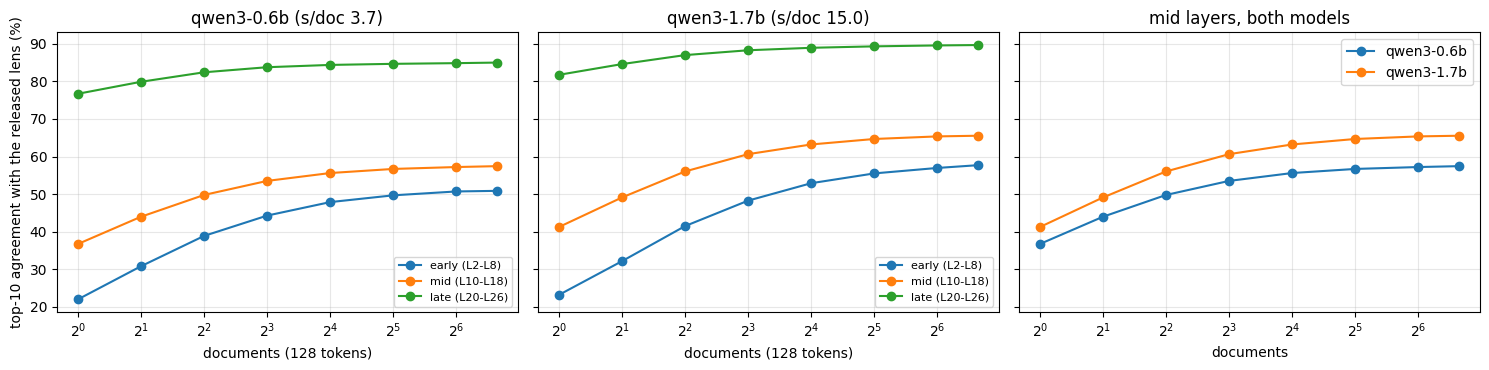

docs               1     2     4     8     16    32    64    100
model      band                                                 
qwen3-0.6b early  21.9  30.8  38.9  44.3  47.9  49.7  50.7  50.9
           late   76.7  79.9  82.4  83.8  84.4  84.7  84.9  85.0
           mid    36.7  44.0  49.8  53.5  55.6  56.7  57.2  57.4
qwen3-1.7b early  23.1  32.1  41.5  48.3  52.9  55.5  57.0  57.7
           late   81.8  84.6  87.0  88.3  89.0  89.3  89.6  89.7
           mid    41.2  49.1  56.0  60.6  63.2  64.7  65.4  65.5

per-layer table: top10_curve_per_layer.csv. se is across random subsets of the same 100 documents (overlapping for n >= 32), so it understates the true spread.
{'qwen3-0.6b': '3.70 s/doc', 'qwen3-1.7b': '14.95 s/doc'}


In [ ]:
import matplotlib.pyplot as plt
def bands(layers):
    k = max(1, len(layers) // 3); return {"early": layers[:k], "mid": layers[k:len(layers) - k], "late": layers[len(layers) - k:]}
rows = []
fig, axs = plt.subplots(1, len(MODELS) + 1, figsize=(5 * (len(MODELS) + 1), 3.8), sharey=True)
for ax, mid in zip(axs, MODELS):
    layers, res = RESULTS[mid]
    for band, Ls in bands(layers).items():
        m = [100 * np.mean([res[(L, n)][0] for L in Ls]) for n in NS]; ax.plot(NS, m, "o-", label=f"{band} (L{Ls[0]}-L{Ls[-1]})")
        rows += [{"model": slug(mid), "band": band, "docs": n, "top-10 (%)": v} for n, v in zip(NS, m)]
    ax.set_xscale("log", base=2); ax.set_title(f"{slug(mid)} (s/doc {SECS[mid]:.1f})"); ax.set_xlabel("documents (128 tokens)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
axs[0].set_ylabel("top-10 agreement with the released lens (%)")
for mid in MODELS:
    layers, res = RESULTS[mid]; Ls = bands(layers)["mid"]; axs[-1].plot(NS, [100 * np.mean([res[(L, n)][0] for L in Ls]) for n in NS], "o-", label=slug(mid))
axs[-1].set_xscale("log", base=2); axs[-1].set_title("mid layers, both models"); axs[-1].set_xlabel("documents"); axs[-1].grid(alpha=.3); axs[-1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/top10_curve.png", dpi=150); plt.show()
CURVE = pd.DataFrame(rows); tab = CURVE.pivot_table(index=["model", "band"], columns="docs", values="top-10 (%)"); display(tab.round(1))
PER = pd.DataFrame([{"model": slug(m), "layer": L, "docs": n, "top-10 (%)": 100 * RESULTS[m][1][(L, n)][0], "se (pts)": 100 * RESULTS[m][1][(L, n)][1]} for m in MODELS for L in RESULTS[m][0] for n in NS])
CURVE.to_csv(f"{OUT}/top10_curve_bands.csv", index=False); PER.to_csv(f"{OUT}/top10_curve_per_layer.csv", index=False)
print("per-layer table: top10_curve_per_layer.csv. se is across random subsets of the same 100 documents (overlapping for n >= 32), so it understates the true spread.")
print({slug(m): f"{SECS[m]:.2f} s/doc" for m in MODELS})

In [ ]:
# ===== Diagnose: why do the curves plateau? (run after section 4 of this notebook; ~2-4 min) =====
mid = MODELS[0]                                   # change to MODELS[1] to repeat for the 1.7B
b = load_bundle(mid); REFD = load_ref(mid); d = b["d"]
b["layers"] = [L for L in range(LAYER_STEP, b["n"] - 1, LAYER_STEP) if L in REFD]; layers = b["layers"]
POLES = make_poles(b, layers, SEED); I_d = torch.eye(d, device=dev)
top = lambda L, M: read_logits(b, POLES[L] @ M.float().to(dev).T).topk(10, dim=1).indices
agree = lambda A, B: float((A[:, :, None] == B[:, None, :]).any(-1).float().mean())
REFTOP = {L: top(L, REFD[L]) for L in layers}

# A. what is in the released file? (meta may name the model, corpus, document length, number of documents)
rt = fn = None; files = []
if mid in REF_OVERRIDE: rt, fn = REF_OVERRIDE[mid]
else:
    for t in ("model", "dataset"):
        try: files = list_repo_files("stdlogits/rs-lenses", repo_type=t)
        except Exception: continue
        hits = [f for f in files if slug(mid) in f.lower().replace("_", "-") and "r-lens" in f.lower() and f.endswith(".pt")]
        if hits: rt, fn = t, hits[0]; break
print("released file:", fn)
try: raw = torch.load(hf_hub_download("stdlogits/rs-lenses", fn, repo_type=rt), weights_only=True)
except Exception as e: print("weights_only load failed:", type(e).__name__); raw = {}
print("top-level keys:", list(raw.keys()) if isinstance(raw, dict) else type(raw))
for k, v in (raw.items() if isinstance(raw, dict) else []):
    if k != "J": print(f"  {k}:", tuple(v.shape) if torch.is_tensor(v) else v)
print("files next to it:", sorted(f for f in files if fn and os.path.dirname(f) == os.path.dirname(fn)))
print(f"released lens has layers {min(REFD)}..{max(REFD)} ({len(REFD)}); the model has {b['n']} layers")

# B. is there a layer-index offset? our 100-doc lens read against the released lens of neighbouring layers
adir = f"{RUN}/{slug(mid)}"; S = {L: torch.zeros(d, d, device=dev) for L in layers}
for i in range(N_DOCS):
    f = torch.load(f"{adir}/doc_{i:03d}.pt", weights_only=True)
    for L in layers: S[L] += f[L].float().to(dev) / N_DOCS
cosf = lambda X, Y: float((X * Y).sum() / (X.norm() * Y.norm()))
rows = []
for L in layers:
    r = {"L": L}
    for j in (-2, -1, 0, 1, 2):
        if L + j in REFD: r[f"ours vs REF[L{j:+d}] top-10"] = agree(top(L, S[L]), top(L, REFD[L + j])); r[f"cos {j:+d}"] = cosf(S[L], REFD[L + j].float().to(dev))
    r["REF[L-1] vs REF[L] top-10 (neighbour baseline)"] = agree(top(L, REFD[L - 1]), REFTOP[L]) if L - 1 in REFD else float("nan")
    r["REF[L+1] vs REF[L] top-10 (neighbour baseline)"] = agree(top(L, REFD[L + 1]), REFTOP[L]) if L + 1 in REFD else float("nan")
    rows.append(r)
pd.set_option("display.width", 250); display(pd.DataFrame(rows).set_index("L").round(2))
# scale and identity: does the released lens look like ours plus a multiple of the identity?
print("L, ||S||/sqrt(d), ||R||/sqrt(d), cos(S,R), cos(S+a I, R) with the best a:")
for L in layers[::3]:
    R = REFD[L].float().to(dev); a = float(((R - S[L]) * I_d).sum() / d)
    print(f"  L{L}: {float(S[L].norm()) / math.sqrt(d):.3f}  {float(R.norm()) / math.sqrt(d):.3f}  {cosf(S[L], R):.3f}  {cosf(S[L] + a * I_d, R):.3f} (a={a:.3f})")

# C. document length: the same 16 documents at 128 tokens vs a longer cut
def fit_mean(rows_, n_docs):
    acc = Accumulator({"out": target_layers("R", "out", b["n"])}, d, device="cuda")
    for i, ids in enumerate(rows_):
        torch.set_float32_matmul_precision("high")
        try: TR.lens_doc("R", b["stack"], torch.tensor(ids), acc, i % 2); torch.cuda.synchronize()
        finally: torch.set_float32_matmul_precision("highest")
    out = {L: ((acc.sums[("out", 0)][L] + acc.sums[("out", 1)][L]) / n_docs).clone() for L in layers}; del acc; torch.cuda.empty_cache(); return out
def band_score(M):
    sc = {L: agree(top(L, M[L]), REFTOP[L]) for L in layers}; k = max(1, len(layers) // 3)
    return {"early": np.mean([sc[L] for L in layers[:k]]), "mid": np.mean([sc[L] for L in layers[k:len(layers) - k]]), "late": np.mean([sc[L] for L in layers[-k:]])}
res = []
for T in (256, 512):
    long = [r for r in lens_docs(CORPUS_DIR / "dclm.jsonl", b["tok"], 800, T, SKIP_FIRST + 2) if len(r) >= T][:16]
    if len(long) < 16: print(f"T={T}: only {len(long)} documents long enough; skipping"); continue
    a = band_score(fit_mean([r[:T_FIT] for r in long], 16)); c = band_score(fit_mean(long, 16))
    res.append({"T": T, **{f"{k} @128": 100 * v for k, v in a.items()}, **{f"{k} @T": 100 * v for k, v in c.items()}})
display(pd.DataFrame(res).set_index("T").round(1)) if res else None
print("""how to read:
 B: if 'ours vs REF[L+j]' peaks at some j != 0, the released lens uses a different layer boundary: shift the reference by j and re-score.
 B: if the neighbour baselines are about as high as our plateau (50-60%), a one-layer offset would explain it.
 A: any meta naming a different checkpoint (for example a Base model), corpus or document length is a setup mismatch to copy.
 C: if '@T' beats '@128' by several points on the same documents, longer fit documents move us toward the released lens.""")


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

reference lens for Qwen/Qwen3-0.6B: model:qwen3-0.6b-base/r-lens/lens.pt
released file: qwen3-0.6b-base/r-lens/lens.pt
top-level keys: ['J', 'n_prompts', 'source_layers', 'd_model', 'provenance']
  n_prompts: 1000
  source_layers: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27]
  d_model: 1024
  provenance: {'model_id': 'Qwen/Qwen3-0.6B-Base', 'dataset_id': 'HuggingFaceFW/dclm_100BT-shuffled@2fa015e4044ec442a0734e89658cdcc538d10dd4', 'rows': [0, 1000], 'rows_sha256': 'ca09a4d8081c7a077060a74e22e226b1c83a275927fcd9f0f14c2416d5273c94', 'n_prompts': 1000, 't_max': 128, 'skip_first': 16, 'config_json': '{"estimator": "relp", "rules": {"ln_rule": "decoder-layer RMSNorm rsqrt held constant", "identity_rule": "act(g) as (act(g)/g)\\u00b7dg", "half_rule": 0.5, "qk_norms": "true derivative", "attention": "true derivative"}, "lens": "R", "target": "out", "positions": "summed over offsets, seeded at positions [16, T-1)", "documents": "equal w

,ours vs REF[L-2] top-10,cos -2,ours vs REF[L-1] top-10,cos -1,ours vs REF[L+0] top-10,cos +0,ours vs REF[L+1] top-10,cos +1,ours vs REF[L+2] top-10,cos +2,REF[L-1] vs REF[L] top-10 (neighbour baseline),REF[L+1] vs REF[L] top-10 (neighbour baseline)
L,,,,,,,,,,,,
2,0.28,0.79,0.32,0.84,0.48,0.90,0.30,0.82,0.27,0.80,0.47,0.37
4,0.23,0.77,0.39,0.87,0.53,0.92,0.42,0.87,0.34,0.83,0.53,0.56
6,0.36,0.84,0.44,0.88,0.53,0.92,0.42,0.87,0.38,0.84,0.60,0.59
8,0.35,0.85,0.43,0.89,0.49,0.92,0.33,0.84,0.26,0.79,0.64,0.39
10,0.24,0.76,0.38,0.87,0.55,0.93,0.41,0.87,0.36,0.85,0.53,0.56
12,0.34,0.85,0.43,0.89,0.54,0.93,0.44,0.90,0.34,0.85,0.60,0.61
14,0.34,0.86,0.38,0.89,0.51,0.94,0.32,0.87,0.27,0.83,0.52,0.40
16,0.25,0.83,0.42,0.91,0.59,0.96,0.43,0.91,0.34,0.87,0.52,0.51
18,0.34,0.88,0.43,0.92,0.68,0.98,0.51,0.94,0.43,0.90,0.51,0.56


L, ||S||/sqrt(d), ||R||/sqrt(d), cos(S,R), cos(S+a I, R) with the best a:
  L2: 4.047  4.019  0.905  0.905 (a=-0.006)
  L8: 2.994  2.993  0.921  0.921 (a=-0.012)
  L14: 2.604  2.580  0.938  0.938 (a=-0.007)
  L20: 1.516  1.488  0.983  0.983 (a=-0.016)
  L26: 1.140  1.131  0.998  0.998 (a=-0.009)


KeyboardInterrupt: 

In [ ]:
files = []
for t in ("model", "dataset"):
    try: files = list_repo_files("stdlogits/rs-lenses", repo_type=t); rt = t; break
    except Exception: pass
for f in sorted(f for f in files if "qwen" in f.lower() and "r-lens" in f.lower() and f.endswith("lens.pt")):
    prov = torch.load(hf_hub_download("stdlogits/rs-lenses", f, repo_type=rt), weights_only=True, mmap=True).get("provenance", {})
    print(f, "->", {k: prov.get(k) for k in ("model_id", "n_prompts", "t_max", "skip_first")})


qwen3-0.6b-base/r-lens/lens.pt -> {'model_id': 'Qwen/Qwen3-0.6B-Base', 'n_prompts': 1000, 't_max': 128, 'skip_first': 16}


qwen3-0.6b/r-lens/lens.pt: reconstructing file:   0%|          |  0.00B /  117MB            

qwen3-0.6b/r-lens/lens.pt: downloading bytes:           |  0.00B            

qwen3-0.6b/r-lens/lens.pt -> {'model_id': 'Qwen/Qwen3-0.6B', 'n_prompts': 1000, 't_max': 128, 'skip_first': 16}
qwen3-1.7b-base/r-lens/lens.pt -> {'model_id': 'Qwen/Qwen3-1.7B-Base', 'n_prompts': 1000, 't_max': 128, 'skip_first': 16}


qwen3-1.7b/r-lens/lens.pt: reconstructing file:   0%|          |  0.00B /  470MB            

qwen3-1.7b/r-lens/lens.pt: downloading bytes:           |  0.00B            

... (15 outputs left out)

qwen3-8b-base/r-lens/lens.pt -> {'model_id': 'Qwen/Qwen3-8B-Base', 'n_prompts': 1000, 't_max': 128, 'skip_first': 16}


qwen3-8b/r-lens/lens.pt: reconstructing file:   0%|          |  0.00B / 2.42GB            

qwen3-8b/r-lens/lens.pt: downloading bytes:           |  0.00B            

qwen3-8b/r-lens/lens.pt -> {'model_id': 'Qwen/Qwen3-8B', 'n_prompts': 1000, 't_max': 128, 'skip_first': 16}


In [ ]:
# ===== Qwen Base: document-selected lens vs random lens, accuracy printed at 50 docs (run after section 2; skip sections 3-4) =====
RUN_MODELS = ["Qwen/Qwen3-0.6B-Base"]        # add "Qwen/Qwen3-1.7B-Base" once this passes (0.6B: ~6 min for both sets; 1.7B: ~25 min)
N_SET, NS_P, FEAT_FRAC, N_PC = 100, [1, 2, 4, 8, 16, 32, 50], 1 / 3, 10
import hashlib
def load_ref_checked(mid):
    rt = fn = None
    if mid in REF_OVERRIDE: rt, fn = REF_OVERRIDE[mid]
    else:
        for t in ("model", "dataset"):
            try: files = list_repo_files("stdlogits/rs-lenses", repo_type=t)
            except Exception: continue
            hits = [f for f in files if slug(mid) in f.lower().replace("_", "-") and "r-lens" in f.lower() and f.endswith("lens.pt")]
            if hits: rt, fn = t, hits[0]; break
    assert fn, f"no released R-lens found for {mid}"
    FILE = torch.load(hf_hub_download("stdlogits/rs-lenses", fn, repo_type=rt), weights_only=True, mmap=True); prov = FILE.get("provenance", {})
    print(f"reference: {fn} | fitted on {prov.get('model_id')} | n_prompts {prov.get('n_prompts')}, t_max {prov.get('t_max')}, skip_first {prov.get('skip_first')}")
    assert prov.get("model_id") in (None, mid), f"checkpoint mismatch: the lens was fitted on {prov.get('model_id')} but we load {mid}"
    RAW = FILE["J"]
    if isinstance(RAW, dict): items = [(int(re.search(r"(\d+)$", str(k)).group(1)), v) for k, v in RAW.items()]
    elif isinstance(RAW, (list, tuple)): items = list(enumerate(RAW))
    else: items = [(i, RAW[i]) for i in range(RAW.shape[0])]
    return dict(items), prov

@torch.no_grad()
def pool_feats(b, rows, layer):
    cap = {}; h = b["stack"].layers[layer].register_forward_hook(lambda m, i, o: cap.__setitem__("h", o[0] if isinstance(o, tuple) else o))
    vp = TR.valid_positions(len(rows[0])); vp = (torch.nonzero(vp).flatten() if vp.dtype == torch.bool else vp).to(dev); out = []
    try:
        for ids in rows: b["stack"](input_ids=torch.tensor([ids], device=dev)); out.append(cap["h"][0, vp].float().mean(0).cpu().numpy())
    finally: h.remove()
    return np.stack(out)
def herd(X, n):                                   # greedy: add the doc that brings the subset mean closest to the pool mean (prefixes are herded too)
    mu, chosen, s = X.mean(0), [], np.zeros(X.shape[1])
    for j in range(n):
        g = np.linalg.norm((s[None] + X) / (j + 1) - mu, axis=1); g[chosen] = np.inf
        i = int(np.argmin(g)); chosen.append(i); s += X[i]
    return chosen
def fit_rows(b, adir, rows):
    os.makedirs(adir, exist_ok=True); acc = Accumulator({"out": target_layers("R", "out", b["n"])}, b["d"], device="cuda"); ts = []
    for i, ids in enumerate(rows):
        p = f"{adir}/doc_{i:03d}.pt"
        if os.path.exists(p): continue
        for s in acc.sums.values(): s.zero_()
        acc.n_docs = [0, 0]; t0 = time.perf_counter(); torch.set_float32_matmul_precision("high")
        try: TR.lens_doc("R", b["stack"], torch.tensor(ids), acc, 0, **({"dim_batch": DIM_BATCH_FIT} if DIM_BATCH_FIT else {})); torch.cuda.synchronize()
        finally: torch.set_float32_matmul_precision("highest")
        S = acc.sums[("out", 0)]; assert torch.isfinite(S).all(), "non-finite sums"
        torch.save({L: S[L].to(torch.bfloat16).cpu().clone() for L in b["layers"]}, p + ".tmp"); os.replace(p + ".tmp", p); ts.append(time.perf_counter() - t0)
        if i % 10 == 0 or i == len(rows) - 1: print(f"{time.strftime('%H:%M:%S')} {os.path.basename(adir)} doc {i + 1}/{len(rows)} in {ts[-1]:.1f}s", flush=True)
    del acc; torch.cuda.empty_cache(); return float(np.median(ts[1:] or ts or [float("nan")]))
def evaluate(b, adir, REFG, POLES, REFTOP):
    sums = {L: torch.zeros(b["d"], b["d"], device=dev) for L in b["layers"]}; out = {}
    for i in range(N_SET):
        f = torch.load(f"{adir}/doc_{i:03d}.pt", weights_only=True)
        for L in b["layers"]: sums[L] += f[L].float().to(dev)
        if i + 1 in NS_P:
            for L in b["layers"]:
                M = sums[L] / (i + 1); ids = read_logits(b, POLES[L] @ M.T).topk(10, dim=1).indices
                out[(L, i + 1)] = (float((REFTOP[L][:, :, None] == ids[:, None, :]).any(-1).float().mean()), float((M * REFG[L]).sum() / (M.norm() * REFG[L].norm())))
    return out

Q50 = {}
for mid in RUN_MODELS:
    print(f"===== {mid} =====")
    b = load_bundle(mid); REFD, prov = load_ref_checked(mid); d = b["d"]
    b["layers"] = [L for L in range(LAYER_STEP, b["n"] - 1, LAYER_STEP) if L in REFD]; layers = b["layers"]
    POLES = make_poles(b, layers, SEED); REFG = {L: REFD[L].float().to(dev) for L in layers}
    REFTOP = {L: read_logits(b, POLES[L] @ REFG[L].T).topk(10, dim=1).indices for L in layers}
    pool = [r[:T_FIT] for r in lens_docs(CORPUS_DIR / "dclm.jsonl", b["tok"], 1000, 256, SKIP_FIRST + 2) if len(r) >= T_FIT]
    X = pool_feats(b, pool, max(1, round(b["n"] * FEAT_FRAC))); X = (X - X.mean(0)) / (X.std(0) + 1e-6)
    U, S_, _ = np.linalg.svd(X - X.mean(0), full_matrices=False); Z = U[:, :N_PC] * S_[:N_PC]; Z = Z / Z.std(0)
    sel = herd(Z, N_SET); rnd = list(range(N_SET))                       # random = first 50 pool docs in corpus order (the corpus is shuffled)
    gap = lambda idx: float(np.linalg.norm(Z[idx].mean(0)))
    print(f"pool {len(pool)} docs; gap to pool mean in {N_PC} PCs: selected {gap(sel):.3f}, random {gap(rnd):.3f}")
    secs, res = {}, {}
    for tag, idx in (("selected", sel), ("random", rnd)):
        adir = f"{RUN}/{slug(mid)}_{tag}_{hashlib.md5(str(idx).encode()).hexdigest()[:8]}"
        secs[tag] = fit_rows(b, adir, [pool[i] for i in idx]); res[tag] = evaluate(b, adir, REFG, POLES, REFTOP)
    k = max(1, len(layers) // 3); BD = {"early": layers[:k], "mid": layers[k:len(layers) - k], "late": layers[-k:]}
    rows = []
    for n in NS_P:
        r = {"docs": n}
        for tag in ("selected", "random"):
            for band, Ls in BD.items(): r[f"{tag} {band}"] = 100 * np.mean([res[tag][(L, n)][0] for L in Ls])
        r["sel - rand (mid)"] = r["selected mid"] - r["random mid"]; rows.append(r)
    T = pd.DataFrame(rows).set_index("docs"); print(f"top-10 agreement with the released lens (%), {slug(mid)}; median s/doc: selected {secs['selected']:.1f}, random {secs['random']:.1f}")
    display(T.round(1)); T.to_csv(f"{OUT}/q50_{slug(mid)}.csv")
    # sanity checks: cosine to the released lens vs what the released lens's own split-half noise predicts for n docs drawn from its 1000
    sh, N = prov.get("split_half"), prov.get("n_prompts", 1000); rows = []
    for L in layers:
        row = {"L": L, "cos @50 selected": res["selected"][(L, 50)][1], "cos @50 random": res["random"][(L, 50)][1]}
        if sh and L < len(sh): row["expected cos @50 (noise only)"] = 1 / math.sqrt(1 + (N * sh[L] ** 2 / 4) * (1 / 50 - 1 / N))
        rows.append(row)
    C = pd.DataFrame(rows).set_index("L"); display(C.round(3))
    mid_ok = all(T["random mid"].diff().dropna() > -1.0) and all(T["selected mid"].diff().dropna() > -1.0)
    cos_ok = float(C["cos @50 random"].min()) > 0.95
    gapv = float((C["expected cos @50 (noise only)"] - C["cos @50 random"]).median()) if "expected cos @50 (noise only)" in C else float("nan")
    print(f"SANITY  top-10 rises with n for both sets: {'OK' if mid_ok else 'CHECK'} | min cosine at 50 docs {float(C['cos @50 random'].min()):.3f} (the post-trained mismatch gave 0.905 at L2 with 100 docs): {'OK' if cos_ok else 'CHECK'}"
          f" | median (expected - measured) cosine {gapv:+.3f} (about 0 means noise only; the expectation assumes the split-half is |even-odd|/|mean| and error orthogonal to the mean)")
    print(f"selected vs random at 50 docs, mid: {T.loc[50, 'selected mid']:.1f}% vs {T.loc[50, 'random mid']:.1f}% ({T.loc[50, 'sel - rand (mid)']:+.1f} pts, ONE draw each, not a confidence interval)")
    Q50[mid] = (T, C); del b, POLES, REFTOP, REFD, REFG; gc.collect(); torch.cuda.empty_cache()


===== Qwen/Qwen3-0.6B-Base =====


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

reference: qwen3-0.6b-base/r-lens/lens.pt | fitted on Qwen/Qwen3-0.6B-Base | n_prompts 1000, t_max 128, skip_first 16
pool 934 docs; gap to pool mean in 10 PCs: selected 0.017, random 0.218
01:14:35 qwen3-0.6b-base_selected_831db97f doc 1/100 in 3.8s
01:15:12 qwen3-0.6b-base_selected_831db97f doc 11/100 in 3.7s
01:15:49 qwen3-0.6b-base_selected_831db97f doc 21/100 in 3.7s
01:16:26 qwen3-0.6b-base_selected_831db97f doc 31/100 in 3.7s
01:17:03 qwen3-0.6b-base_selected_831db97f doc 41/100 in 3.6s
01:17:40 qwen3-0.6b-base_selected_831db97f doc 51/100 in 3.7s
01:18:16 qwen3-0.6b-base_selected_831db97f doc 61/100 in 3.7s
01:18:53 qwen3-0.6b-base_selected_831db97f doc 71/100 in 3.7s
01:19:30 qwen3-0.6b-base_selected_831db97f doc 81/100 in 3.7s
01:20:06 qwen3-0.6b-base_selected_831db97f doc 91/100 in 3.7s
01:20:39 qwen3-0.6b-base_selected_831db97f doc 100/100 in 3.6s
01:20:47 qwen3-0.6b-base_random_904b9c78 doc 1/100 in 3.7s
01:21:24 qwen3-0.6b-base_random_904b9c78 doc 11/100 in 3.7s
01:22:00 

,selected early,selected mid,selected late,random early,random mid,random late,sel - rand (mid)
docs,,,,,,,
1,40.7,51.5,85.2,40.7,51.5,85.2,0.0
2,43.8,57.5,87.1,47.3,59.5,87.3,-2.0
4,55.5,68.2,90.5,60.7,71.1,91.1,-3.0
8,65.8,77.5,92.9,67.2,76.6,92.4,0.9
16,75.2,83.9,94.8,77.0,83.6,94.8,0.3
32,80.9,87.8,96.2,84.3,88.6,96.2,-0.8
50,83.6,89.2,96.7,86.4,90.6,96.7,-1.4


,cos @50 selected,cos @50 random,expected cos @50 (noise only)
L,,,
2,0.992,0.996,0.993
4,0.994,0.996,0.994
6,0.994,0.996,0.995
8,0.995,0.997,0.996
10,0.997,0.997,0.997
12,0.997,0.998,0.997
14,0.998,0.998,0.998
16,0.999,0.999,0.998
18,0.999,0.999,0.999


SANITY  top-10 rises with n for both sets: OK | min cosine at 50 docs 0.996 (the post-trained mismatch gave 0.905 at L2 with 100 docs): OK | median (expected - measured) cosine -0.000 (about 0 means noise only; the expectation assumes the split-half is |even-odd|/|mean| and error orthogonal to the mean)
selected vs random at 50 docs, mid: 89.2% vs 90.6% (-1.4 pts, ONE draw each, not a confidence interval)


In [ ]:
# ===== 7. Add Qwen3-1.7B-Base and draw the curves (run after section 6; ~50 min for the 1.7B, resumable) =====
# Reuses section-6 routines (load_bundle, load_ref_checked, pool_feats, herd, fit_rows, evaluate) and Q50.
assert "Q50" in globals() and "evaluate" in globals(), "run section 6 first"
import hashlib
TODO = [m for m in ("Qwen/Qwen3-0.6B-Base", "Qwen/Qwen3-1.7B-Base") if m not in Q50]
for mid in TODO:
    print(f"\n===== {mid} =====")
    b = load_bundle(mid); REFD, prov = load_ref_checked(mid)
    b["layers"] = [L for L in range(LAYER_STEP, b["n"] - 1, LAYER_STEP) if L in REFD]; layers = b["layers"]
    POLES = make_poles(b, layers, SEED); REFG = {L: REFD[L].float().to(dev) for L in layers}
    REFTOP = {L: read_logits(b, POLES[L] @ REFG[L].T).topk(10, dim=1).indices for L in layers}
    pool = [r[:T_FIT] for r in lens_docs(CORPUS_DIR / "dclm.jsonl", b["tok"], 1000, 256, SKIP_FIRST + 2) if len(r) >= T_FIT]
    X = pool_feats(b, pool, max(1, round(b["n"] * FEAT_FRAC))); X = (X - X.mean(0)) / (X.std(0) + 1e-6)
    U, S_, _ = np.linalg.svd(X - X.mean(0), full_matrices=False); Z = U[:, :N_PC] * S_[:N_PC]; Z = Z / Z.std(0)
    sel, rnd = herd(Z, N_SET), list(range(N_SET)); secs, res = {}, {}
    for tag, idx in (("selected", sel), ("random", rnd)):
        adir = f"{RUN}/{slug(mid)}_{tag}_{hashlib.md5(str(idx).encode()).hexdigest()[:8]}"
        secs[tag] = fit_rows(b, adir, [pool[i] for i in idx]); res[tag] = evaluate(b, adir, REFG, POLES, REFTOP)
    k = max(1, len(layers) // 3); BD = {"early": layers[:k], "mid": layers[k:len(layers) - k], "late": layers[-k:]}
    rows = []
    for n in NS_P:
        r = {"docs": n}
        for tag in ("selected", "random"):
            for band, Ls in BD.items(): r[f"{tag} {band}"] = 100 * np.mean([res[tag][(L, n)][0] for L in Ls])
        r["sel - rand (mid)"] = r["selected mid"] - r["random mid"]; rows.append(r)
    T = pd.DataFrame(rows).set_index("docs"); C = pd.DataFrame([{"L": L, "cos selected": res["selected"][(L, NS_P[-1])][1], "cos random": res["random"][(L, NS_P[-1])][1]} for L in layers]).set_index("L")
    print(f"top-10 (%), {slug(mid)}; median s/doc selected {secs['selected']:.1f}, random {secs['random']:.1f}"); display(T.round(1)); T.to_csv(f"{OUT}/q50_{slug(mid)}.csv")
    print(f"min cosine to the released lens at {NS_P[-1]} docs: {float(C['cos random'].min()):.3f}")
    Q50[mid] = (T, C); del b, POLES, REFTOP, REFD, REFG; gc.collect(); torch.cuda.empty_cache()

import matplotlib.pyplot as plt
MM = [m for m in ("Qwen/Qwen3-0.6B-Base", "Qwen/Qwen3-1.7B-Base") if m in Q50]
fig, axs = plt.subplots(1, len(MM) + 1, figsize=(5 * (len(MM) + 1), 3.9), sharey=True)
for ax, mid in zip(axs, MM):
    T = Q50[mid][0]
    for band in ("early", "mid", "late"):
        ax.plot(T.index, T[f"random {band}"], "o-", label=f"{band} random")
        ax.plot(T.index, T[f"selected {band}"], "x--", label=f"{band} selected", alpha=.7)
    ax.set_xscale("log", base=2); ax.set_title(slug(mid)); ax.set_xlabel("documents (128 tokens)"); ax.grid(alpha=.3); ax.legend(fontsize=7)
axs[0].set_ylabel("top-10 agreement with the released lens (%)")
for mid in MM: axs[-1].plot(Q50[mid][0].index, Q50[mid][0]["random mid"], "o-", label=slug(mid))
axs[-1].set_xscale("log", base=2); axs[-1].set_title("mid layers, random docs"); axs[-1].set_xlabel("documents"); axs[-1].grid(alpha=.3); axs[-1].legend()
plt.tight_layout(); plt.savefig(f"{OUT}/qwen_curves.png", dpi=150); plt.show()
print("\nmid-layer top-10 (%), random docs, by model and n:")
display(pd.DataFrame({slug(m): Q50[m][0]["random mid"] for m in MM}).round(1))
print("selected - random at the mid layers (pts), one draw each:")
display(pd.DataFrame({slug(m): Q50[m][0]["sel - rand (mid)"] for m in MM}).round(1))


===== Qwen/Qwen3-1.7B-Base =====


config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.68k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

reference: qwen3-1.7b-base/r-lens/lens.pt | fitted on Qwen/Qwen3-1.7B-Base | n_prompts 1000, t_max 128, skip_first 16
01:30:15 qwen3-1.7b-base_selected_1fd035ce doc 1/100 in 15.3s
01:32:43 qwen3-1.7b-base_selected_1fd035ce doc 11/100 in 14.8s
01:35:11 qwen3-1.7b-base_selected_1fd035ce doc 21/100 in 14.8s
01:37:39 qwen3-1.7b-base_selected_1fd035ce doc 31/100 in 14.9s
01:40:06 qwen3-1.7b-base_selected_1fd035ce doc 41/100 in 14.7s
01:42:35 qwen3-1.7b-base_selected_1fd035ce doc 51/100 in 14.8s
01:45:02 qwen3-1.7b-base_selected_1fd035ce doc 61/100 in 14.7s
01:47:30 qwen3-1.7b-base_selected_1fd035ce doc 71/100 in 14.8s
01:49:59 qwen3-1.7b-base_selected_1fd035ce doc 81/100 in 14.8s
01:52:26 qwen3-1.7b-base_selected_1fd035ce doc 91/100 in 14.8s
01:54:40 qwen3-1.7b-base_selected_1fd035ce doc 100/100 in 14.8s
01:55:06 qwen3-1.7b-base_random_904b9c78 doc 1/100 in 14.7s


KeyboardInterrupt: 

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

reference: qwen3-0.6b-base/r-lens/lens.pt | fitted on Qwen/Qwen3-0.6B-Base | n_prompts 1000, t_max 128, skip_first 16
qwen3-0.6b-base random: 100 docs on disk


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

reference: qwen3-1.7b-base/r-lens/lens.pt | fitted on Qwen/Qwen3-1.7B-Base | n_prompts 1000, t_max 128, skip_first 16
qwen3-1.7b-base selected: 100 docs on disk


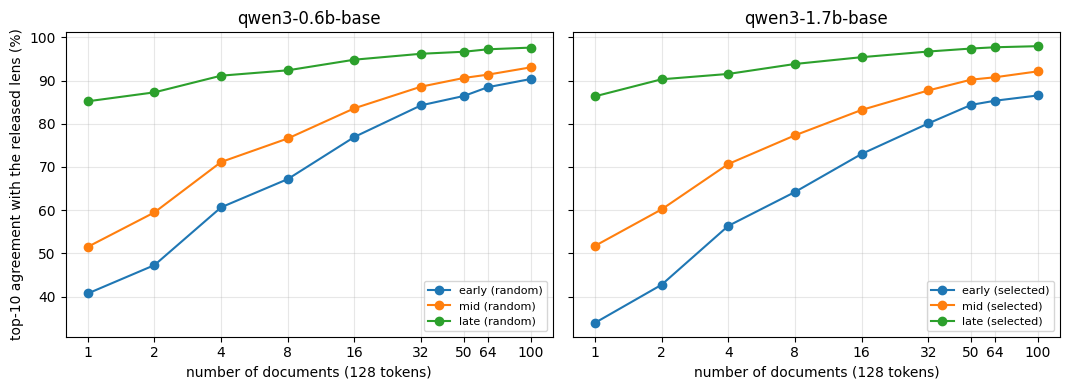

qwen3-0.6b-base random (100 docs): mid n=1:51.5%  n=2:59.5%  n=4:71.1%  n=8:76.6%  n=16:83.6%  n=32:88.6%  n=50:90.6%  n=64:91.4%  n=100:93.0%
qwen3-1.7b-base selected (100 docs): mid n=1:51.7%  n=2:60.2%  n=4:70.7%  n=8:77.3%  n=16:83.2%  n=32:87.7%  n=50:90.2%  n=64:90.8%  n=100:92.1%


In [ ]:
# ===== Curves from whatever is already fitted on disk (no fitting; reuses section-6 routines and RUN/OUT) =====
import glob
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, FixedFormatter
PLOT = [("Qwen/Qwen3-0.6B-Base", ["random"]), ("Qwen/Qwen3-1.7B-Base", ["selected"])]   # (model, arms); one curve each
NS_C = [n for n in (1, 2, 4, 8, 16, 32, 50, 64, 100) if n <= N_SET]

CURVES = {}
for mid, arms in PLOT:
    try:
        b = load_bundle(mid); REFD, _ = load_ref_checked(mid)
    except Exception as e:
        print(f"skip {mid}: {type(e).__name__} {e}"); continue
    b["layers"] = [L for L in range(LAYER_STEP, b["n"] - 1, LAYER_STEP) if L in REFD]; layers = b["layers"]
    POLES = make_poles(b, layers, SEED); REFG = {L: REFD[L].float().to(dev) for L in layers}
    REFTOP = {L: read_logits(b, POLES[L] @ REFG[L].T).topk(10, dim=1).indices for L in layers}
    k = max(1, len(layers) // 3); BD = {"early": layers[:k], "mid": layers[k:len(layers) - k], "late": layers[-k:]}
    for tag in arms:
        hits = sorted(glob.glob(f"{RUN}/{slug(mid)}_{tag}_*/doc_*.pt"))
        if not hits: print(f"{slug(mid)} {tag}: nothing on disk"); continue
        adir = os.path.dirname(hits[0]); have = sorted(int(re.search(r"doc_(\d+)", h).group(1)) for h in hits)
        m = next((i for i in range(len(have)) if have[i] != i), len(have))      # first contiguous run
        if m < 1: continue
        sums = {L: torch.zeros(b["d"], b["d"], device=dev) for L in layers}; curve = {}
        for i in range(m):
            f = torch.load(f"{adir}/doc_{i:03d}.pt", weights_only=True)
            for L in layers: sums[L] += f[L].float().to(dev)
            if (i + 1) in NS_C or i + 1 == m:
                for band, Ls in BD.items():
                    vals = [float((REFTOP[L][:, :, None] == read_logits(b, POLES[L] @ (sums[L] / (i + 1)).T).topk(10, 1).indices[:, None, :]).any(-1).float().mean()) for L in Ls]
                    curve[(band, i + 1)] = 100 * np.mean(vals)
        CURVES[(slug(mid), tag)] = (m, curve); print(f"{slug(mid)} {tag}: {m} docs on disk")
    del b, POLES, REFTOP, REFD, REFG; gc.collect(); torch.cuda.empty_cache()

models = [m for m in dict.fromkeys(slug(mm) for mm, _ in PLOT) if any(k[0] == m for k in CURVES)]
fig, axs = plt.subplots(1, len(models), figsize=(5.4 * len(models), 4), sharey=True, squeeze=False)
allx = sorted({n for (_, cur) in CURVES.values() for (_, n) in cur})
for ax, m in zip(axs[0], models):
    for (mm, tag), (_, cur) in CURVES.items():
        if mm != m: continue
        for band in ("early", "mid", "late"):
            xs = sorted({n for (bd, n) in cur if bd == band}); ax.plot(xs, [cur[(band, n)] for n in xs], "o-", label=f"{band} ({tag})")
    ax.set_xscale("log", base=2); ax.xaxis.set_major_locator(FixedLocator(allx)); ax.xaxis.set_major_formatter(FixedFormatter([str(n) for n in allx]))
    ax.minorticks_off(); ax.set_title(m); ax.set_xlabel("number of documents (128 tokens)"); ax.grid(alpha=.3); ax.legend(fontsize=8)
axs[0][0].set_ylabel("top-10 agreement with the released lens (%)")
plt.tight_layout(); plt.savefig(f"{OUT}/qwen_curve_ondisk.png", dpi=150); plt.show()
for (m, tag), (n, cur) in CURVES.items():
    print(f"{m} {tag} ({n} docs): mid " + "  ".join(f"n={k}:{cur[('mid', k)]:.1f}%" for (bd, k) in sorted(cur) if bd == "mid"))
